In [227]:
import numpy as np
import h5py
import matplotlib.pyplot as plt
import astropy.units as u
import astropy
from astropy.table import Table
from astropy.io import fits
from astropy.io.misc.hdf5 import write_table_hdf5
import os
from matplotlib.lines import Line2D

import Lovell2023_evs as evs
from Lovell2023_stats import compute_conf_ints, eddington_bias
from Lovell2023_stellar import apply_fs_distribution

DATA_PRODUCTS_PATH = 'raid/scratch/work/alberttg/Masters_project/Data_products'

FIG_DIR = "/raid/scratch/work/alberttg/Masters_project/Plots"

In [228]:

with fits.open('/raid/scratch/work/alberttg/Masters_project/Data_products/First_sample_table.fits') as hdu:

    sample_table = hdu[1].data
sample_table = Table(sample_table)

log_mass_50 = sample_table["stellar_mass_50"].data 
# log_mass_16 = sample_table["stellar_mass_16"].data
# log_mass_84 = sample_table["stellar_mass_84"].data
# log_mass_upper_err = log_mass_84 - log_mass_50
# log_mass_lower_err = log_mass_50 - log_mass_16
redshift = sample_table["input_redshift"].data


In [ ]:
def redshift_bins(table, ax, marker_style, marker_size, colour, edgecolor='black', edgewidth=1):
    """
    Bin the data by redshift and compute the median and bootstrap errors for each bin.

    Parameters
    ----------
    table : fits table
        Sample table containing data for masses and redshifts.
    ax : matplotlib.axes.Axes
        The axes on which to plot the binned data.
    marker_style : str
        Square or diamond or circle points for the plot.
    marker_size : float
        Size of the points for the plot.
    colour : str
        Color of the points for the plot.
    """
    bins = [[6.5, 7.5], [7.5, 8.5], [8.5, 9.5], [9.5, 10.5], [10.5, 11.5], [11.5, 13.5]]
    # We've set z=6.5 as the minimum and the highest well-measured redshift galaxies at 13.5.

    redshifts = table["input_redshift"].data
    y_values = table["stellar_mass_50"].data
    y_upper_err = table["stellar_mass_84"].data - y_values
    y_lower_err = y_values - table["stellar_mass_16"].data

    bin_centers = []
    maximums = []
    upper_errors = []
    lower_errors = []

    for i in range(len(bins)):
        bin_mask = (redshifts >= bins[i][0]) & (redshifts < bins[i][1])
        bin_redshifts = redshifts[bin_mask]
        bin_y_values = y_values[bin_mask]
        bin_y_upper_err = y_upper_err[bin_mask]
        bin_y_lower_err = y_lower_err[bin_mask]

        
        max = np.max(bin_y_values)
        # print(bin_y_upper_err[np.where(bin_y_values == max)])
        upper_err = np.abs(bin_y_upper_err[np.where(bin_y_values == max)[0][0]]) # ------------ one of them is negative????
        lower_err = bin_y_lower_err[np.where(bin_y_values == max)[0][0]]
        bin_center = np.median(bins[i])

        bin_centers.append(bin_center)
        maximums.append(max)
        upper_errors.append(upper_err)
        lower_errors.append(lower_err)

    #print(maximums)
    #print(upper_errors)
    #print(lower_errors)

    ax.errorbar(bin_centers, maximums, yerr=[lower_errors, upper_errors], 
                fmt=marker_style, markersize=marker_size,
                markeredgecolor=edgecolor, markeredgewidth=edgewidth,
                color=colour, linestyle="none",
                label=f"Median of binned redshifts", zorder=3
            )
    
    return bin_centers, maximums, upper_errors, lower_errors


In [230]:
with h5py.File('/raid/scratch/work/alberttg/Masters_project/Data_products/evs_lightcone_behroozi.h5','r') as hf:
    log10m = hf['log10m'][:]
    f = hf['f'][:]
    F = hf['F'][:]
    N = hf['N'][:]
    z = hf['z'][:]
    

whole_sky = (41252.96 * u.deg**2).to(u.arcmin**2)
survey_area = 648.9 * u.arcmin**2
fsky = float(survey_area / whole_sky)
phi_max = evs.apply_fsky(N, f, F, fsky)

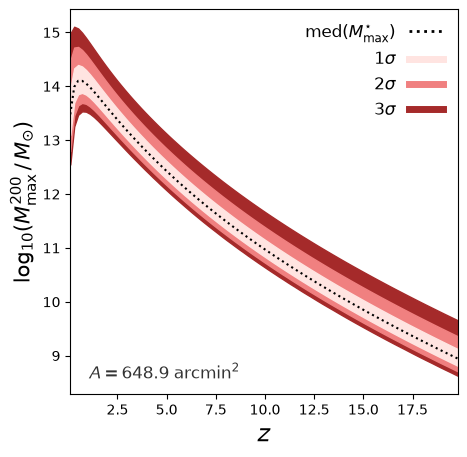

In [231]:
CI_mhalo = compute_conf_ints(phi_max, log10m)

colors = ['brown','lightcoral','mistyrose']

fig, ax = plt.subplots(1, 1, figsize=(5,5))

ax.fill_between(z, CI_mhalo[:,0], CI_mhalo[:,6], alpha=1, color=colors[0])
ax.fill_between(z, CI_mhalo[:,1], CI_mhalo[:,5], alpha=1, color=colors[1])
ax.fill_between(z, CI_mhalo[:,2], CI_mhalo[:,4], alpha=1, color=colors[2])
ax.plot(z, CI_mhalo[:,3], linestyle='dotted', c='black')

ax.set_xlim(0.1, 19.8);
ax.set_xlabel('$z$', size=17)
ax.set_ylabel('$\mathrm{log_{10}}(M^{200}_{\mathrm{max}} \,/\, M_{\odot})$', size=15)
ax.text(0.05, 0.04, '$A = 648.9 \; \mathrm{arcmin}^2$', size=12, color='black', alpha=0.8, transform = ax.transAxes)

line1 = plt.Line2D((0,1),(0,0), color=colors[0], linewidth=5)
line2 = plt.Line2D((0,1),(0,0), color=colors[1], linewidth=5)
line3 = plt.Line2D((0,1),(0,0), color=colors[2], linewidth=5)
line4 = plt.Line2D((0,1),(0,0), color='black', linestyle='dotted', linewidth=2)
#line_dummy = plt.Line2D((0,1),(0,0), color='white')
leg = ax.legend(handles=[line4,line3,line2,line1], 
           labels=['$\mathrm{med}(M^{\star}_{\mathrm{max}})$',
               '$1\sigma$', '$2\sigma$', '$3\sigma$'],
                frameon=False, loc='upper right', fontsize=12, ncol=1)

vp = leg._legend_box._children[-1]._children[0] 
for c in vp._children: c._children.reverse() 
vp.align="right" 

In [232]:
f_b = 0.16
CI_baryon = np.log10(10**CI_mhalo * f_b)

_N = int(1e4)
mstar_pdf = np.vstack([apply_fs_distribution(_phi_max, log10m, _N=_N, method='lognormal') \
        for _phi_max in phi_max])

In [233]:
CIs = compute_conf_ints(mstar_pdf, log10m)

fig, ax = plt.subplots(1, 1, figsize=(5,5))

colors = ['brown','lightcoral','mistyrose']

ax.fill_between(z, CIs[:,0], CIs[:,6], alpha=1, color=colors[0])
ax.fill_between(z, CIs[:,1], CIs[:,5], alpha=1, color=colors[1])
ax.fill_between(z, CIs[:,2], CIs[:,4], alpha=1, color=colors[2])
ax.plot(z, CIs[:,3], linestyle='dotted', c='black')
ax.plot(z, CI_baryon[:,6], linestyle='dashed', color='black')



ax.set_xlim(6.0, 14.0); 
# ax.set_ylim(5.4, 11.8)
ax.set_xlabel('$z$', size=17)
ax.set_ylabel('$\mathrm{log_{10}}(M^{\star}_{\mathrm{max}} \,/\, M_{\odot})$', size=15)
ax.text(0.05, 0.04, '$A = 648.9 \; \mathrm{arcmin}^2$', size=12, color='black', alpha=0.8, transform = ax.transAxes)

redshift_bins(sample_table, ax, 'o', 6, 'orange')


line1 = plt.Line2D((0,1),(0,0), color=colors[0], linewidth=5)
line2 = plt.Line2D((0,1),(0,0), color=colors[1], linewidth=5)
line3 = plt.Line2D((0,1),(0,0), color=colors[2], linewidth=5)
line4 = plt.Line2D((0,1),(0,0), color='black', linestyle='dotted', linewidth=2)
line5 = plt.Line2D((0,1),(0,0), color='black', linestyle='dashed', linewidth=2)
#line_dummy = plt.Line2D((0,1),(0,0), color='white')
bagpipes = plt.Line2D((0,1),(0,0), marker='o', markerfacecolor='tab:orange', markeredgecolor='black', markersize=8)

leg = ax.legend(handles=[line4,line5, bagpipes,line3,line2,line1], 
           labels=['$\mathrm{med}(M^{\star}_{\mathrm{max}})$','$f_{\mathrm{b}}$ $+3\sigma$', 'Bagpipes',
               '$1\sigma$', '$2\sigma$', '$3\sigma$'],
                frameon=False, loc='upper right', fontsize=12, ncol=2)

vp = leg._legend_box._children[-1]._children[0] 
for c in vp._children: c._children.reverse() 
vp.align="right"

fig_path = os.path.join(FIG_DIR, "EVS_stellar_mass_vs_redshift.png")
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.close(fig)
 

[np.float64(10.691956340447344), np.float64(9.336037478348091), np.float64(9.577123984417224), np.float64(9.501323139076822), np.float64(10.493374031869843), np.float64(9.536602610467758)]
[np.float64(0.030212069808850828), np.float64(0.038820678109170004), np.float64(0.06488895733834354), np.float64(0.029415138302045563), np.float64(0.8312604461404334), np.float64(0.15964567040712652)]
